In [2]:
# ============================================================
# PROJETO DE ESTÁGIO - ENADE 2021 Ciência da Computação
# Notebook 01 - Carregar e explorar os dados
# ============================================================

# Importar as bibliotecas que vamos usar
import pandas as pd   # pandas: a principal ferramenta para trabalhar com dados em tabela

# ------------------------------------------------------------
# 1. Definir onde estão os arquivos de dados
# ------------------------------------------------------------
# A letra "r" antes das aspas evita problemas com as barras invertidas (\) do Windows
pasta_dados = r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\dados\microdados_enade_2021\microdados_Enade_2021_LGPD\2.DADOS"

# ------------------------------------------------------------
# 2. Carregar o arquivo arq1 (tem o CO_GRUPO, que identifica o curso)
# ------------------------------------------------------------
# sep=";"      -> as colunas são separadas por ponto e vírgula (o manual do INEP pede isso)
# encoding     -> como o texto está codificado (latin-1 costuma funcionar nos dados do INEP)
# decimal="."  -> os números decimais usam ponto
arq1 = pd.read_csv(
    pasta_dados + r"\microdados2021_arq1.txt",
    sep=";",
    encoding="latin-1",
    decimal="."
)

# Mostrar as primeiras 5 linhas do arq1
print("===== ARQ1 - Caracterização do curso =====")
print("Formato (linhas, colunas):", arq1.shape)
print("Colunas:", list(arq1.columns))
arq1.head()


===== ARQ1 - Caracterização do curso =====
Formato (linhas, colunas): (489866, 10)
Colunas: ['NU_ANO', 'CO_CURSO', 'CO_IES', 'CO_CATEGAD', 'CO_ORGACAD', 'CO_GRUPO', 'CO_MODALIDADE', 'CO_MUNIC_CURSO', 'CO_UF_CURSO', 'CO_REGIAO_CURSO']


,NU_ANO,CO_CURSO,CO_IES,CO_CATEGAD,CO_ORGACAD,CO_GRUPO,CO_MODALIDADE,CO_MUNIC_CURSO,CO_UF_CURSO,CO_REGIAO_CURSO
0,2021,6,1,1,10028,2001,1,5103403,51,5
1,2021,6,1,1,10028,2001,1,5103403,51,5
2,2021,6,1,1,10028,2001,1,5103403,51,5
3,2021,6,1,1,10028,2001,1,5103403,51,5
4,2021,6,1,1,10028,2001,1,5103403,51,5


In [3]:
# ============================================================
# 3. Filtrar apenas os cursos de Ciência da Computação (Bacharelado)
# ============================================================
# No dicionário, CO_GRUPO = 4004 significa "Ciência da Computação (Bacharelado)"
cc_cursos = arq1[arq1["CO_GRUPO"] == 4004]

print("===== Cursos de Ciencia da Computacao (Bacharelado) =====")
print("Quantidade de registros de curso CC:", cc_cursos.shape[0])

# Guardar a lista de códigos de curso (CO_CURSO) que são de Ciência da Computação
codigos_cc = cc_cursos["CO_CURSO"].unique()
print("Quantidade de cursos CC diferentes:", len(codigos_cc))

# ============================================================
# 4. Carregar o arq3 (respostas, gabaritos e notas)
# ============================================================
arq3 = pd.read_csv(
    pasta_dados + r"\microdados2021_arq3.txt",
    sep=";",
    encoding="latin-1",
    decimal="."
)

print("===== ARQ3 - Respostas e gabaritos (todos os cursos) =====")
print("Formato (linhas, colunas):", arq3.shape)

# ============================================================
# 5. Filtrar o arq3 para manter só os alunos de Ciência da Computação
# ============================================================
cc_dados = arq3[arq3["CO_CURSO"].isin(codigos_cc)]

print("===== Dados de prova - so Ciencia da Computacao =====")
print("Formato (linhas, colunas):", cc_dados.shape)
print("Ou seja:", cc_dados.shape[0], "alunos de Ciencia da Computacao")

# Mostrar as colunas de vetores que nos interessam (respostas e gabaritos)
colunas_interesse = [
    "CO_CURSO",
    "DS_VT_GAB_OCE_FIN",  # gabarito do componente específico (27 questões)
    "DS_VT_ESC_OCE",      # o que o aluno marcou
    "DS_VT_ACE_OCE",      # acertos (0=errou, 1=acertou)
    "TP_PRES"             # tipo de presença
]
cc_dados[colunas_interesse].head()


===== Cursos de Ciencia da Computacao (Bacharelado) =====
Quantidade de registros de curso CC: 12733
Quantidade de cursos CC diferentes: 329
===== ARQ3 - Respostas e gabaritos (todos os cursos) =====
Formato (linhas, colunas): (489866, 52)
===== Dados de prova - so Ciencia da Computacao =====
Formato (linhas, colunas): (12733, 52)
Ou seja: 12733 alunos de Ciencia da Computacao


C:\Users\joaop\AppData\Local\Temp\ipykernel_3376\995390541.py:17: DtypeWarning: Columns (12: DS_VT_ESC_OFG, 14: DS_VT_ESC_OCE, 15: DS_VT_ACE_OCE, 43: CO_RS_I1, 44: CO_RS_I2, 45: CO_RS_I3, 46: CO_RS_I4, 47: CO_RS_I5, 48: CO_RS_I6, 49: CO_RS_I7, 50: CO_RS_I8, 51: CO_RS_I9) have mixed types. Specify dtype option on import or set low_memory=False.
  arq3 = pd.read_csv(


,CO_CURSO,DS_VT_GAB_OCE_FIN,DS_VT_ESC_OCE,DS_VT_ACE_OCE,TP_PRES
43,1187671,EBDXXCCBXEDAXACEXADBZEEXZCD,...........................,990009000900090008009800,555
55,13595,EBDXXCCBXEDAXACEXADBZEEXZCD,...........................,990009000900090008009800,555
148,13881,EBDXXCCBXEDAXACEXADBZEEXZCD,...........................,990009000900090008009800,555
289,7142,EBDXXCCBXEDAXACEXADBZEEXZCD,DCCECAEDBCCBDBDBDCBADABDBDB,990009000900090008009800,555
296,102186,EBDXXCCBXEDAXACEXADBZEEXZCD,BDABEAEEDAADACABAEAABBAADDE,990009000900090008009800,555


In [4]:
# ============================================================
# 6. Diagnóstico: entender a qualidade dos dados
# ============================================================

# Quantos alunos de cada tipo de presença (TP_PRES)?
print("===== Distribuicao de TP_PRES (tipo de presenca) =====")
print(cc_dados["TP_PRES"].value_counts())
print()

# Quantos alunos têm o vetor de resposta vazio (nao responderam)?
# Vamos checar quantos têm "." no comeco do vetor de escolha
respostas_vazias = cc_dados["DS_VT_ESC_OCE"].astype(str).str.startswith(".")
print("Alunos com resposta aparentemente vazia:", respostas_vazias.sum())
print("Alunos com alguma resposta preenchida:", (~respostas_vazias).sum())
print()

# Ver o tamanho dos vetores (quantas questoes tem o componente especifico)
print("===== Tamanho dos vetores =====")
print("Tamanho do gabarito (primeiro aluno):", len(str(cc_dados["DS_VT_GAB_OCE_FIN"].iloc[0])))


===== Distribuicao de TP_PRES (tipo de presenca) =====
TP_PRES
555    9993
222    2580
556     126
444      18
334      16
Name: count, dtype: int64

Alunos com resposta aparentemente vazia: 21
Alunos com alguma resposta preenchida: 12712

===== Tamanho dos vetores =====
Tamanho do gabarito (primeiro aluno): 27


In [5]:
# ============================================================
# 7. Limpeza: manter apenas alunos com resultado válido (TP_PRES = 555)
# ============================================================
# 555 = "Presente com resultado válido" (segundo o dicionário do INEP)
cc_validos = cc_dados[cc_dados["TP_PRES"] == 555].copy()

print("Antes da limpeza:", cc_dados.shape[0], "registros")
print("Depois da limpeza (so validos):", cc_validos.shape[0], "alunos")
print()

# ============================================================
# 8. Checar o gabarito: quais questoes foram anuladas?
# ============================================================
# O gabarito é o mesmo para todos os alunos. Vamos pegar o primeiro.
gabarito = str(cc_validos["DS_VT_GAB_OCE_FIN"].iloc[0])
print("Gabarito do Componente Especifico:")
print(gabarito)
print()

# Mostrar questao por questao (posicao e letra)
print("Questao | Gabarito")
for i, letra in enumerate(gabarito, start=1):
    status = ""
    if letra in ("X", "Z"):
        status = " <-- ANULADA"
    print(f"   {i:2d}   |   {letra}{status}")


Antes da limpeza: 12733 registros
Depois da limpeza (so validos): 9993 alunos

Gabarito do Componente Especifico:
EBDXXCCBXEDAXACEXADBZEEXZCD

Questao | Gabarito
    1   |   E
    2   |   B
    3   |   D
    4   |   X <-- ANULADA
    5   |   X <-- ANULADA
    6   |   C
    7   |   C
    8   |   B
    9   |   X <-- ANULADA
   10   |   E
   11   |   D
   12   |   A
   13   |   X <-- ANULADA
   14   |   A
   15   |   C
   16   |   E
   17   |   X <-- ANULADA
   18   |   A
   19   |   D
   20   |   B
   21   |   Z <-- ANULADA
   22   |   E
   23   |   E
   24   |   X <-- ANULADA
   25   |   Z <-- ANULADA
   26   |   C
   27   |   D


In [6]:
# ============================================================
# 9. INDICE DE DIFICULDADE (Teoria Classica dos Testes) - versao corrigida
# ============================================================
# Usamos a coluna DS_VT_ACE_OCE: 0=errou, 1=acertou, 8 ou 9=anulada

import pandas as pd

# 1) Primeiro, remover alunos cujo vetor de acertos esta vazio (NaN)
cc_validos = cc_validos[cc_validos["DS_VT_ACE_OCE"].notna()].copy()
print("Alunos apos remover vetores vazios:", cc_validos.shape[0])

# 2) Pegar a coluna de acertos como texto (string)
acertos_texto = cc_validos["DS_VT_ACE_OCE"].astype(str)

# 3) Checar se todos os vetores tem o mesmo tamanho (27)
tamanhos = acertos_texto.str.len().value_counts()
print("Tamanhos dos vetores encontrados:")
print(tamanhos)
print()

# 4) Transformar cada caractere do vetor numa coluna separada
acertos = acertos_texto.apply(lambda x: pd.Series(list(x)))

# 5) Dar nome as colunas: Q1, Q2, Q3... ate Q27
acertos.columns = [f"Q{i}" for i in range(1, acertos.shape[1] + 1)]

print("Formato da tabela de acertos:", acertos.shape)
print("(linhas = alunos, colunas = questoes)")
print()

acertos.head()


Alunos apos remover vetores vazios: 9987
Tamanhos dos vetores encontrados:
DS_VT_ACE_OCE
27    4068
26    2324
25    2011
24    1584
Name: count, dtype: int64

Formato da tabela de acertos: (9987, 27)
(linhas = alunos, colunas = questoes)



,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q18,Q19,Q20,Q21,Q22,Q23,Q24,Q25,Q26,Q27
43,9,9,0,0,0,9,0,0,0,9,...,8,0,0,9,8,0,0,NaN,NaN,NaN
55,9,9,0,0,0,9,0,0,0,9,...,8,0,0,9,8,0,0,NaN,NaN,NaN
148,9,9,0,0,0,9,0,0,0,9,...,8,0,0,9,8,0,0,NaN,NaN,NaN
289,9,9,0,0,0,9,0,0,0,9,...,8,0,0,9,8,0,0,NaN,NaN,NaN
296,9,9,0,0,0,9,0,0,0,9,...,8,0,0,9,8,0,0,NaN,NaN,NaN


In [7]:
# ============================================================
# 10. INVESTIGAR: por que os vetores tem tamanhos diferentes?
# ============================================================

# Vamos olhar alguns vetores de acerto COMPLETOS, com tamanhos diferentes
acertos_texto = cc_validos["DS_VT_ACE_OCE"].astype(str)

# Separar exemplos de cada tamanho
for tamanho in [27, 26, 25, 24]:
    exemplo = acertos_texto[acertos_texto.str.len() == tamanho].iloc[0]
    print(f"Tamanho {tamanho}: '{exemplo}'")

print()

# Comparar com o gabarito (que tem 27 posicoes)
gabarito = str(cc_validos["DS_VT_GAB_OCE_FIN"].iloc[0])
print(f"Gabarito ({len(gabarito)} posicoes): '{gabarito}'")
print()

# Ver tambem os vetores de ESCOLHA (o que o aluno marcou) desses mesmos casos
print("===== Vetores de ESCOLHA (o que o aluno marcou) =====")
escolha_texto = cc_validos["DS_VT_ESC_OCE"].astype(str)
print("Tamanhos dos vetores de escolha:")
print(escolha_texto.str.len().value_counts())


Tamanho 27: '100990009000900090008009800'
Tamanho 26: '10990019000900090008009800'
Tamanho 25: '1990009000900090008009800'
Tamanho 24: '990009000900090008009800'

Gabarito (27 posicoes): 'EBDXXCCBXEDAXACEXADBZEEXZCD'

===== Vetores de ESCOLHA (o que o aluno marcou) =====
Tamanhos dos vetores de escolha:
DS_VT_ESC_OCE
27    9987
Name: count, dtype: int64


In [8]:
# ============================================================
# 11. SOLUCAO: calcular acertos comparando ESCOLHA x GABARITO
# ============================================================
# O vetor DS_VT_ESC_OCE (escolha do aluno) tem 27 caracteres certinhos.
# Vamos comparar cada resposta com o gabarito para montar a tabela de acertos.

import pandas as pd
import numpy as np

# Gabarito oficial (27 questoes)
gabarito = str(cc_validos["DS_VT_GAB_OCE_FIN"].iloc[0])
print("Gabarito:", gabarito, f"({len(gabarito)} questoes)")
print()

# Vetor de escolha de cada aluno (o que marcou)
escolha_texto = cc_validos["DS_VT_ESC_OCE"].astype(str)

# Quebrar a escolha em colunas Q1..Q27
escolhas = escolha_texto.apply(lambda x: pd.Series(list(x)))
escolhas.columns = [f"Q{i}" for i in range(1, 28)]

print("Formato da tabela de escolhas:", escolhas.shape)
print()

# Agora montar a tabela de ACERTOS comparando com o gabarito
# Para cada questao i: acerto = 1 se o aluno marcou a letra do gabarito, senao 0
acertos = pd.DataFrame(index=escolhas.index)

for i in range(1, 28):
    letra_certa = gabarito[i-1]  # letra correta da questao i
    coluna = f"Q{i}"
    if letra_certa in ("X", "Z"):
        # Questao anulada: marca como NaN (nao entra na analise)
        acertos[coluna] = np.nan
    else:
        # 1 se acertou, 0 se errou
        acertos[coluna] = (escolhas[coluna] == letra_certa).astype(int)

print("Formato da tabela de acertos:", acertos.shape)
print("Questoes anuladas (viram NaN):", [f"Q{i}" for i in range(1,28) if gabarito[i-1] in ("X","Z")])
print()

acertos.head()


Gabarito: EBDXXCCBXEDAXACEXADBZEEXZCD (27 questoes)

Formato da tabela de escolhas: (9987, 27)

Formato da tabela de acertos: (9987, 27)
Questoes anuladas (viram NaN): ['Q4', 'Q5', 'Q9', 'Q13', 'Q17', 'Q21', 'Q24', 'Q25']



,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q18,Q19,Q20,Q21,Q22,Q23,Q24,Q25,Q26,Q27
43,0,0,0,NaN,NaN,0,0,0,NaN,0,...,0,0,0,NaN,0,0,NaN,NaN,0,0
55,0,0,0,NaN,NaN,0,0,0,NaN,0,...,0,0,0,NaN,0,0,NaN,NaN,0,0
148,0,0,0,NaN,NaN,0,0,0,NaN,0,...,0,0,0,NaN,0,0,NaN,NaN,0,0
289,0,0,0,NaN,NaN,0,0,0,NaN,0,...,0,0,0,NaN,0,0,NaN,NaN,0,0
296,0,0,0,NaN,NaN,0,0,0,NaN,0,...,0,0,0,NaN,0,0,NaN,NaN,0,0


In [9]:
# ============================================================
# 12. INDICE DE DIFICULDADE (p) - Teoria Classica dos Testes
# ============================================================
# O indice de dificuldade (p) de uma questao = proporcao de alunos que acertaram
#   p perto de 1,0 -> questao FACIL (quase todos acertaram)
#   p perto de 0,0 -> questao DIFICIL (quase ninguem acertou)
#
# Como os acertos sao 0 e 1, a media da coluna JA e o indice de dificuldade.
# O .mean() ignora os NaN automaticamente (entao questoes anuladas sao puladas).

dificuldade = acertos.mean()

print("===== INDICE DE DIFICULDADE POR QUESTAO =====")
print("(proporcao de alunos que acertaram cada questao)")
print()

# Mostrar de forma organizada, da mais dificil para a mais facil
dificuldade_ordenada = dificuldade.sort_values()

for questao, p in dificuldade_ordenada.items():
    if pd.isna(p):
        print(f"{questao}: ANULADA")
    else:
        # Classificar a dificuldade
        if p < 0.30:
            nivel = "MUITO DIFICIL"
        elif p < 0.50:
            nivel = "DIFICIL"
        elif p < 0.70:
            nivel = "MEDIA"
        else:
            nivel = "FACIL"
        print(f"{questao}: {p:.1%} acertaram  ->  {nivel}")


===== INDICE DE DIFICULDADE POR QUESTAO =====
(proporcao de alunos que acertaram cada questao)

Q18: 15.3% acertaram  ->  MUITO DIFICIL
Q26: 22.8% acertaram  ->  MUITO DIFICIL
Q23: 23.1% acertaram  ->  MUITO DIFICIL
Q6: 25.0% acertaram  ->  MUITO DIFICIL
Q16: 28.4% acertaram  ->  MUITO DIFICIL
Q20: 33.8% acertaram  ->  DIFICIL
Q12: 35.0% acertaram  ->  DIFICIL
Q11: 38.1% acertaram  ->  DIFICIL
Q2: 40.2% acertaram  ->  DIFICIL
Q1: 40.7% acertaram  ->  DIFICIL
Q10: 42.3% acertaram  ->  DIFICIL
Q15: 44.9% acertaram  ->  DIFICIL
Q22: 45.4% acertaram  ->  DIFICIL
Q7: 51.0% acertaram  ->  MEDIA
Q19: 51.3% acertaram  ->  MEDIA
Q27: 51.4% acertaram  ->  MEDIA
Q14: 53.0% acertaram  ->  MEDIA
Q8: 62.7% acertaram  ->  MEDIA
Q3: 64.5% acertaram  ->  MEDIA
Q4: ANULADA
Q5: ANULADA
Q9: ANULADA
Q13: ANULADA
Q17: ANULADA
Q21: ANULADA
Q24: ANULADA
Q25: ANULADA


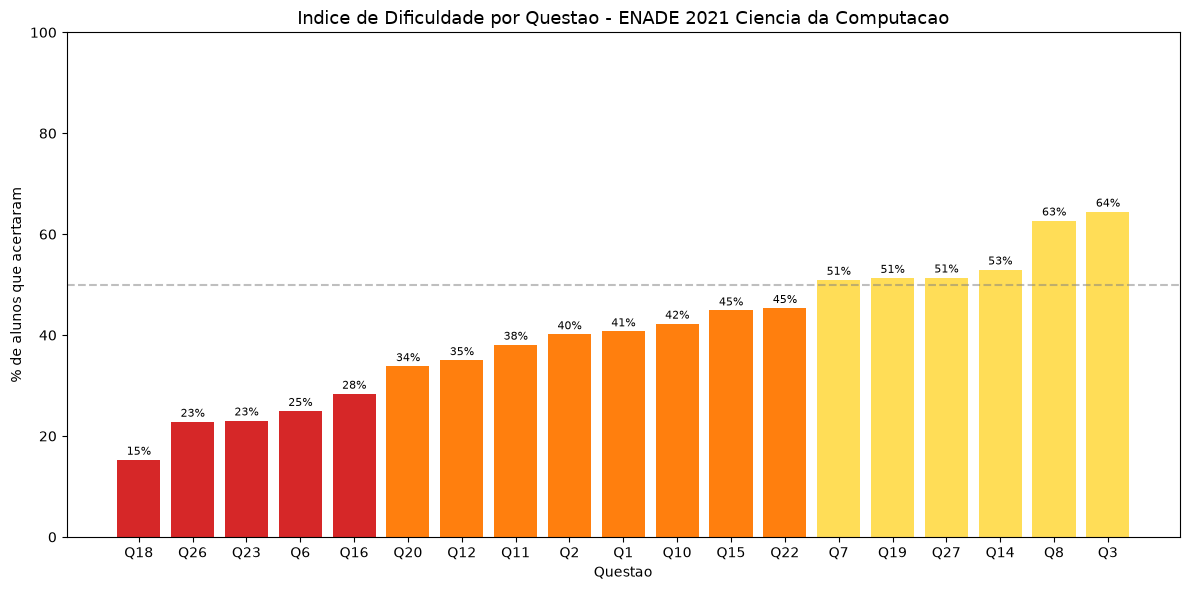

Grafico salvo na pasta 'resultados'!


In [10]:
# ============================================================
# 13. GRAFICO: Indice de Dificuldade por Questao
# ============================================================
import matplotlib.pyplot as plt

# Pegar so as questoes validas (sem as anuladas / NaN) e ordenar
dificuldade_validas = dificuldade.dropna().sort_values()

# Criar o grafico
plt.figure(figsize=(12, 6))

# Cores: vermelho para dificil, amarelo para media, verde para facil
cores = []
for p in dificuldade_validas:
    if p < 0.30:
        cores.append("#d62728")   # vermelho (muito dificil)
    elif p < 0.50:
        cores.append("#ff7f0e")   # laranja (dificil)
    elif p < 0.70:
        cores.append("#ffdd57")   # amarelo (media)
    else:
        cores.append("#2ca02c")   # verde (facil)

barras = plt.bar(dificuldade_validas.index, dificuldade_validas.values * 100, color=cores)

# Titulos e rotulos
plt.title("Indice de Dificuldade por Questao - ENADE 2021 Ciencia da Computacao", fontsize=13)
plt.xlabel("Questao")
plt.ylabel("% de alunos que acertaram")
plt.axhline(y=50, color="gray", linestyle="--", alpha=0.5)  # linha de referencia em 50%
plt.ylim(0, 100)

# Mostrar o valor em cima de cada barra
for barra, valor in zip(barras, dificuldade_validas.values * 100):
    plt.text(barra.get_x() + barra.get_width()/2, valor + 1, f"{valor:.0f}%",
             ha="center", fontsize=8)

plt.tight_layout()

# Salvar o grafico na pasta resultados
plt.savefig(r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\dificuldade_questoes.png", dpi=150)

plt.show()

print("Grafico salvo na pasta 'resultados'!")


In [11]:
# ============================================================
# 14. CONFIRMAR a numeracao: comparar gabarito dos dados x gabarito oficial PDF
# ============================================================

# Gabarito que o codigo leu dos microdados (27 posicoes)
gabarito_dados = str(cc_validos["DS_VT_GAB_OCE_FIN"].iloc[0])

# Gabarito oficial do PDF (questoes 9 a 35 da prova = as 27 do componente especifico)
# X = anulada
gabarito_pdf = "EBDBACCDEBDBECCBCEDAEACEBAD"  # <-- vou te explicar abaixo

# Na verdade, vamos usar o gabarito oficial correto do PDF:
# Q9=E Q10=B Q11=D Q12=B Q13=E Q14=C Q15=C Q16=B Q17=C Q18=E Q19=D Q20=A
# Q21=E Q22=A Q23=C Q24=E Q25=B Q26=A Q27=D Q28=B Q29=X Q30=E Q31=E Q32=A Q33=X Q34=C Q35=D
gabarito_pdf = "EBDBECCBCEDAEACEBADBXEEAXCD"

print("Posicao | Dados | PDF | Bate?")
print("-" * 40)
for i in range(27):
    questao_prova = i + 9  # Q1 analise = Questao 9 prova
    g_dados = gabarito_dados[i]
    g_pdf = gabarito_pdf[i]
    # Considera anuladas (X/Z nos dados) como equivalentes a X no pdf
    bate = "OK" if (g_dados == g_pdf) or (g_dados in "XZ" and g_pdf == "X") else "<<< DIFERENTE"
    print(f"  Q{i+1} (prova {questao_prova})  |   {g_dados}   |  {g_pdf}  | {bate}")


Posicao | Dados | PDF | Bate?
----------------------------------------
  Q1 (prova 9)  |   E   |  E  | OK
  Q2 (prova 10)  |   B   |  B  | OK
  Q3 (prova 11)  |   D   |  D  | OK
  Q4 (prova 12)  |   X   |  B  | <<< DIFERENTE
  Q5 (prova 13)  |   X   |  E  | <<< DIFERENTE
  Q6 (prova 14)  |   C   |  C  | OK
  Q7 (prova 15)  |   C   |  C  | OK
  Q8 (prova 16)  |   B   |  B  | OK
  Q9 (prova 17)  |   X   |  C  | <<< DIFERENTE
  Q10 (prova 18)  |   E   |  E  | OK
  Q11 (prova 19)  |   D   |  D  | OK
  Q12 (prova 20)  |   A   |  A  | OK
  Q13 (prova 21)  |   X   |  E  | <<< DIFERENTE
  Q14 (prova 22)  |   A   |  A  | OK
  Q15 (prova 23)  |   C   |  C  | OK
  Q16 (prova 24)  |   E   |  E  | OK
  Q17 (prova 25)  |   X   |  B  | <<< DIFERENTE
  Q18 (prova 26)  |   A   |  A  | OK
  Q19 (prova 27)  |   D   |  D  | OK
  Q20 (prova 28)  |   B   |  B  | OK
  Q21 (prova 29)  |   Z   |  X  | OK
  Q22 (prova 30)  |   E   |  E  | OK
  Q23 (prova 31)  |   E   |  E  | OK
  Q24 (prova 32)  |   X   |  A  |

In [12]:
# Salvar a dificuldade de cada questao num arquivo, para usar no notebook do agente
dificuldade_df = dificuldade.reset_index()
dificuldade_df.columns = ["questao_analise_cod", "indice_dificuldade"]
# Transformar "Q1" em numero 1
dificuldade_df["questao_analise"] = dificuldade_df["questao_analise_cod"].str.replace("Q", "").astype(int)

caminho_saida = r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\dificuldade.csv"
dificuldade_df.to_csv(caminho_saida, index=False)
print("Dificuldade salva em:", caminho_saida)
print(dificuldade_df)


Dificuldade salva em: C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\dificuldade.csv
   questao_analise_cod  indice_dificuldade  questao_analise
0                   Q1            0.407330                1
1                   Q2            0.401522                2
2                   Q3            0.644538                3
3                   Q4                 NaN                4
4                   Q5                 NaN                5
5                   Q6            0.249625                6
6                   Q7            0.509562                7
7                   Q8            0.626915                8
8                   Q9                 NaN                9
9                  Q10            0.422549               10
10                 Q11            0.380795               11
11                 Q12            0.350255               12
12                 Q13                 NaN               13
13                 Q14            0.529889

In [13]:
# ============================================================
# INDICE DE DISCRIMINACAO (metodo de Kelley - 27%)
# ============================================================
import numpy as np

# 1) Calcular a nota total de cada aluno (soma de acertos nas questoes validas)
#    O .sum(axis=1) soma cada linha (cada aluno), ignorando NaN (anuladas)
nota_total = acertos.sum(axis=1)

# 2) Definir os grupos: 27% melhores e 27% piores
n_alunos = len(nota_total)
tamanho_grupo = int(n_alunos * 0.27)

# Ordenar alunos pela nota
ordem = nota_total.sort_values(ascending=False)
indices_melhores = ordem.head(tamanho_grupo).index
indices_piores = ordem.tail(tamanho_grupo).index

print(f"Total de alunos: {n_alunos}")
print(f"Grupo superior (27%): {tamanho_grupo} alunos")
print(f"Grupo inferior (27%): {tamanho_grupo} alunos")
print()

# 3) Para cada questao, calcular a discriminacao
discriminacao = {}
for questao in acertos.columns:
    acerto_melhores = acertos.loc[indices_melhores, questao].mean()
    acerto_piores = acertos.loc[indices_piores, questao].mean()
    if np.isnan(acerto_melhores):  # questao anulada
        discriminacao[questao] = np.nan
    else:
        discriminacao[questao] = acerto_melhores - acerto_piores

# 4) Mostrar resultado ordenado
import pandas as pd
disc_series = pd.Series(discriminacao).dropna().sort_values(ascending=False)

print("===== INDICE DE DISCRIMINACAO POR QUESTAO =====")
for questao, d in disc_series.items():
    if d >= 0.40:
        nivel = "OTIMA"
    elif d >= 0.30:
        nivel = "BOA"
    elif d >= 0.20:
        nivel = "RAZOAVEL"
    else:
        nivel = "FRACA"
    print(f"{questao}: D = {d:.2f}  ->  {nivel}")


Total de alunos: 9987
Grupo superior (27%): 2696 alunos
Grupo inferior (27%): 2696 alunos

===== INDICE DE DISCRIMINACAO POR QUESTAO =====
Q12: D = 0.63  ->  OTIMA
Q27: D = 0.61  ->  OTIMA
Q3: D = 0.58  ->  OTIMA
Q19: D = 0.57  ->  OTIMA
Q2: D = 0.48  ->  OTIMA
Q14: D = 0.48  ->  OTIMA
Q22: D = 0.47  ->  OTIMA
Q8: D = 0.45  ->  OTIMA
Q20: D = 0.39  ->  BOA
Q10: D = 0.38  ->  BOA
Q7: D = 0.37  ->  BOA
Q23: D = 0.37  ->  BOA
Q16: D = 0.36  ->  BOA
Q15: D = 0.33  ->  BOA
Q11: D = 0.31  ->  BOA
Q1: D = 0.29  ->  RAZOAVEL
Q6: D = 0.28  ->  RAZOAVEL
Q18: D = 0.20  ->  FRACA
Q26: D = 0.19  ->  FRACA


In [14]:
# Salvar a discriminacao para usar no notebook do agente
disc_df = disc_series.reset_index()
disc_df.columns = ["questao_analise_cod", "indice_discriminacao"]
disc_df["questao_analise"] = disc_df["questao_analise_cod"].str.replace("Q", "").astype(int)

caminho_disc = r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\discriminacao.csv"
disc_df.to_csv(caminho_disc, index=False)
print("Discriminacao salva em:", caminho_disc)


Discriminacao salva em: C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\discriminacao.csv


In [15]:
# ============================================================
# ANALISE DE DISTRATORES
# ============================================================
# Para cada questao, ver qual % dos alunos marcou cada alternativa (A,B,C,D,E)
# e destacar o gabarito.

# Recriar a tabela de escolhas (o que cada aluno marcou) no componente especifico
escolha_texto = cc_validos["DS_VT_ESC_OCE"].astype(str)
escolhas = escolha_texto.apply(lambda x: pd.Series(list(x)))
escolhas.columns = [f"Q{i}" for i in range(1, 28)]

gabarito = str(cc_validos["DS_VT_GAB_OCE_FIN"].iloc[0])

# Analisar uma questao especifica para testar: Q18 (a mais dificil)
def analisar_distratores(questao_num):
    coluna = f"Q{questao_num}"
    letra_certa = gabarito[questao_num - 1]
    print(f"===== {coluna} (gabarito: {letra_certa}) =====")
    # Contar quantos marcaram cada alternativa
    contagem = escolhas[coluna].value_counts(normalize=True).sort_index()
    for alternativa, proporcao in contagem.items():
        marca = " <-- GABARITO (correta)" if alternativa == letra_certa else ""
        print(f"  {alternativa}: {proporcao*100:5.1f}%{marca}")
    print()

# Testar com a Q18 (mais dificil) e Q3 (mais facil)
analisar_distratores(18)
analisar_distratores(3)


===== Q18 (gabarito: A) =====
  *:   0.0%
  .:   0.4%
  A:  15.3% <-- GABARITO (correta)
  B:   6.7%
  C:  21.1%
  D:  15.1%
  E:  41.5%

===== Q3 (gabarito: D) =====
  *:   0.1%
  .:   0.3%
  A:  13.5%
  B:   8.9%
  C:   7.5%
  D:  64.5% <-- GABARITO (correta)
  E:   5.3%



In [16]:
# ============================================================
# TABELA MESTRA: juntar dificuldade + discriminacao de todas as questoes
# ============================================================
# Juntar dificuldade e discriminacao
tabela_tct = dificuldade_df.merge(disc_df[["questao_analise", "indice_discriminacao"]],
                                   on="questao_analise", how="left")

# Para cada questao, descobrir o distrator mais marcado (a alternativa errada mais popular)
distrator_info = {}
for q in range(1, 28):
    coluna = f"Q{q}"
    letra_certa = gabarito[q - 1]
    if letra_certa in ("X", "Z"):
        distrator_info[q] = (None, None)
        continue
    contagem = escolhas[coluna].value_counts(normalize=True)
    # remover gabarito e marcas invalidas
    erradas = contagem.drop([letra_certa, "*", "."], errors="ignore")
    if len(erradas) > 0:
        distrator_top = erradas.idxmax()
        distrator_pct = erradas.max() * 100
        distrator_info[q] = (distrator_top, round(distrator_pct, 1))
    else:
        distrator_info[q] = (None, None)

tabela_tct["distrator_mais_marcado"] = tabela_tct["questao_analise"].map(lambda q: distrator_info.get(q, (None,None))[0])
tabela_tct["distrator_pct"] = tabela_tct["questao_analise"].map(lambda q: distrator_info.get(q, (None,None))[1])

# Salvar
caminho_tct = r"C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\tabela_tct_completa.csv"
tabela_tct.to_csv(caminho_tct, index=False)
print("Tabela TCT completa salva em:", caminho_tct)
print()
print(tabela_tct[["questao_analise", "indice_dificuldade", "indice_discriminacao", "distrator_mais_marcado", "distrator_pct"]].to_string(index=False))


Tabela TCT completa salva em: C:\Users\joaop\OneDrive\Área de Trabalho\Projeto Estagio Obrigatorio\resultados\tabela_tct_completa.csv

 questao_analise  indice_dificuldade  indice_discriminacao distrator_mais_marcado  distrator_pct
               1            0.407330              0.289318                      D           21.8
               2            0.401522              0.479970                      A           42.4
               3            0.644538              0.581602                      A           13.5
               4                 NaN                   NaN                    NaN            NaN
               5                 NaN                   NaN                    NaN            NaN
               6            0.249625              0.275964                      A           42.2
               7            0.509562              0.372774                      E           35.4
               8            0.626915              0.451409                      E        